In [19]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Load Hardware Data

# Device selection

In [20]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"
device = "ibm_aachen"
# device = "ibm_kingston"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

/var/folders/bm/v93fcqrd7kq6vwyfqyx20p5w0000gn/T/ipykernel_3937/3737875437.py:12: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)


# Auxiliary lattice plot

8 possible layouts


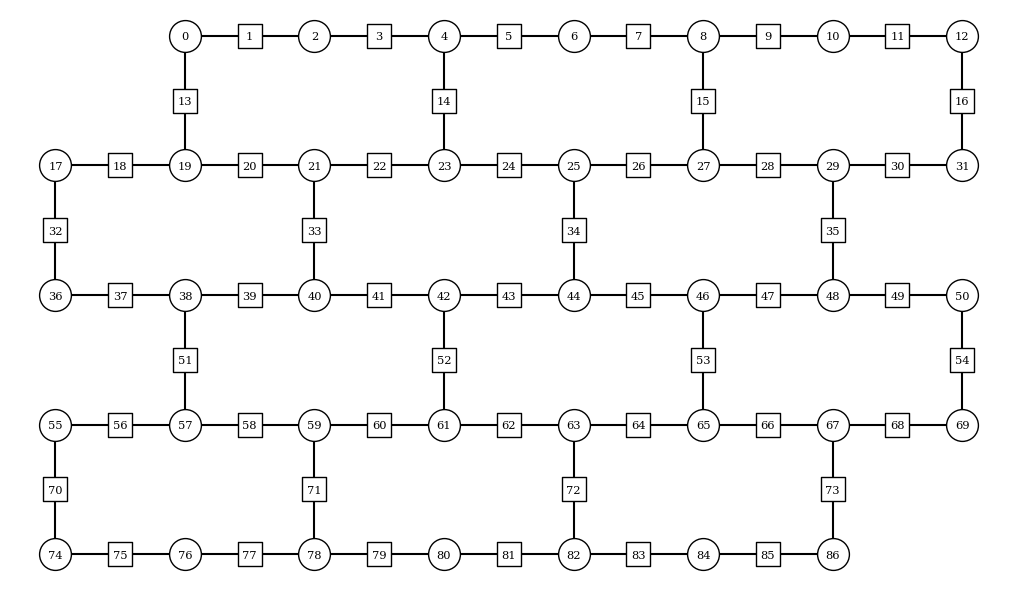

In [21]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 4

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

# Simulation settings

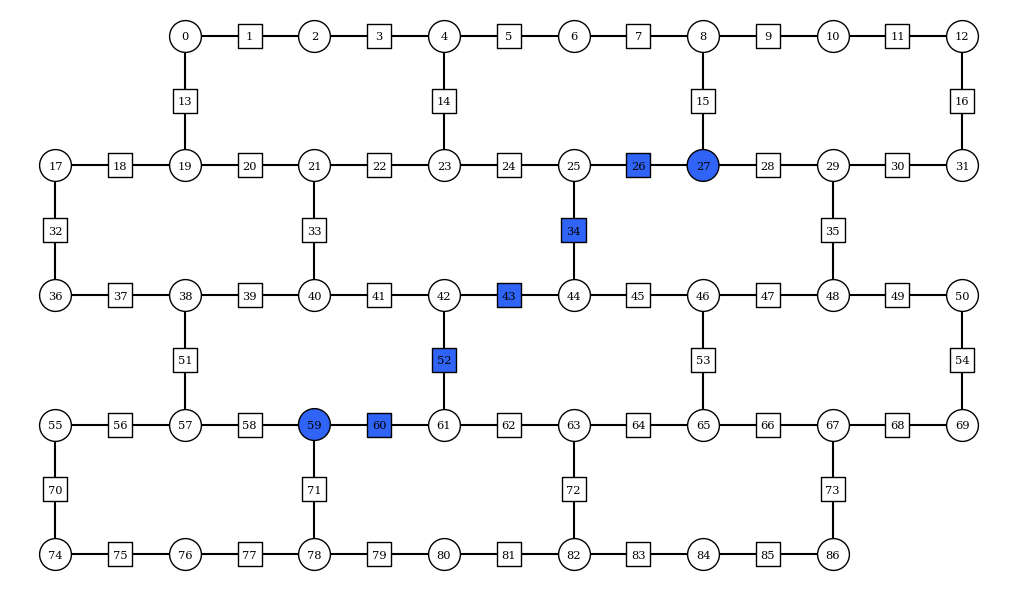

In [22]:
from z2hex.gdd import zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 2.5
h = 1
lamb = 1

x_basis = False

fractional_gates = False

string = [27, 26, 34, 43, 52, 60, 59]
# string = [4, 10, 17, 24, 30]

final_time = 3
dt = 0.15
steps = 20
desired_error = 1e-2

max_layers = 50
adjust_depth = True

shots = 150000
confidence = 0.9

odr = True
postselect_odr = True
flip_threshold = 7
all_or_first_layout_qubit = True
forbidden_qubits = []
max_layouts = 5
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    }
}

execution_database = "z2_hex_jobs_shutdown.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

curated_data_folder_path = "Curated data/"

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string), number_qubits=True)

# Load jobs

In [23]:
from utils.postselection_multithreaded import load_postselected_jobs_obs
import pickle
import os

# Newer jobs include EM in the filename
curated_data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_dd_{sampler_options["dynamical_decoupling"]["enable"]}_pt_{sampler_options["twirling"]["enable_gates"]}_ft_{flip_threshold}_pODR_{postselect_odr}_confidence_{confidence}.pkl")

with open(curated_data_filepath, "rb") as f:
    hardware_observables, hardware_observables_confidence, samples_dicts, postselected_samples_dicts, layouts = pickle.load(f)

# Load TN data

In [24]:
import numpy as np
import os

tn_dt = 0.01
tn_final_time = 8
tn_exp_order = 30
tn_bond_dimension = 128
tn_data_folderpath = "TN Data/"
tn_data_limit = int(final_time / tn_dt)

# tn_data_filepath = os.path.join(tn_data_folderpath, f"converted_data_BUG_g{h:.02f}_m{J:.02f}_ROWS{plaquette_width}_COLS{plaquette_height}_dt{tn_dt:.03f}_Tmax{tn_final_time:.02f}_exp_order{tn_exp_order}_M{tn_bond_dimension:05d}.txt")
tn_data_filepath = os.path.join(tn_data_folderpath, f"converted_data_BUG_g{h:.02f}_m{J:.02f}_{plaquette_width}x{plaquette_height}_dt{tn_dt:.03f}_Tmax{tn_final_time:.02f}_exp_order{tn_exp_order}_M{tn_bond_dimension:05d}.txt")
tn_observables = np.loadtxt(tn_data_filepath)

# Plots

## 2x2

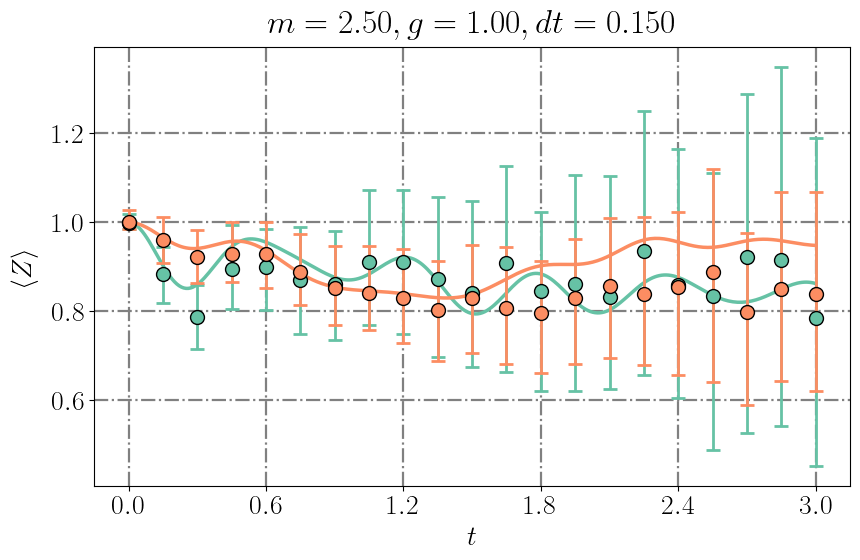

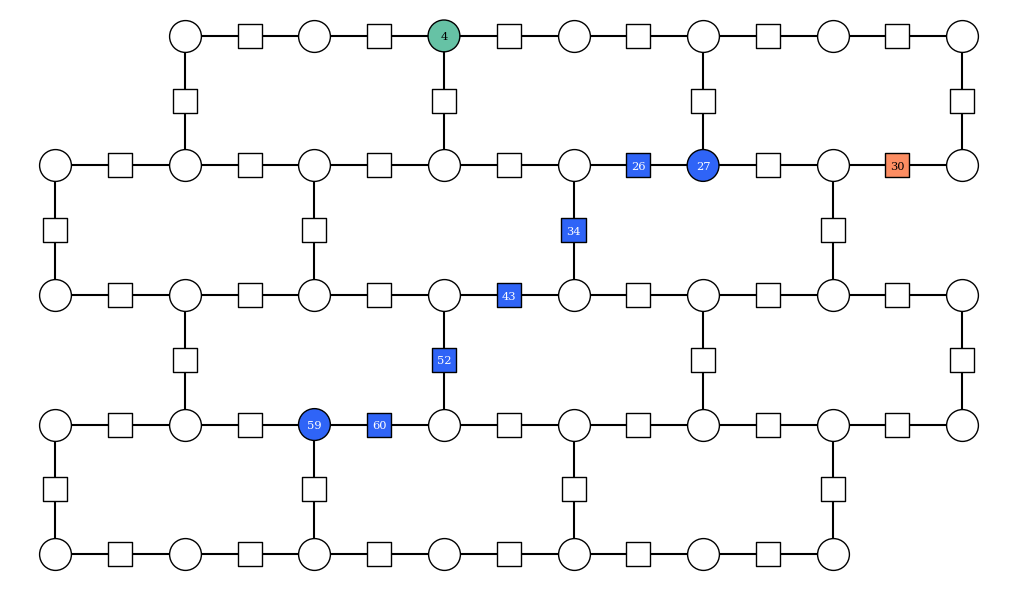

In [25]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [4, 30]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

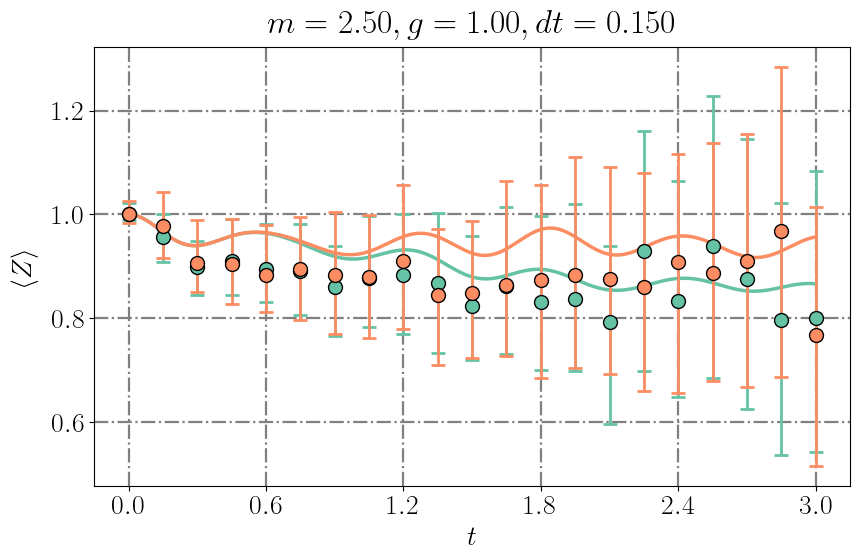

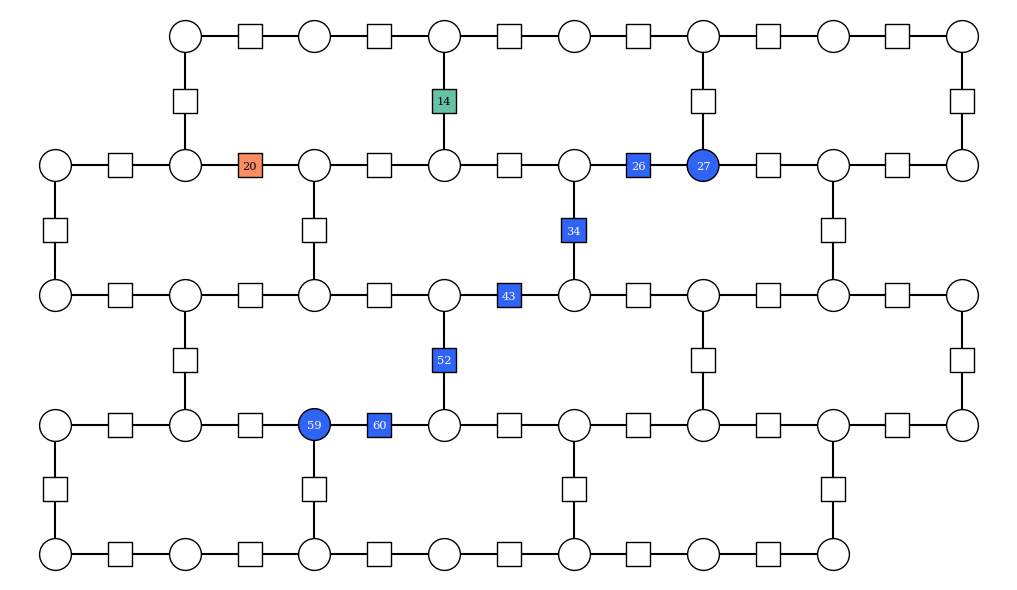

In [26]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [14, 20]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

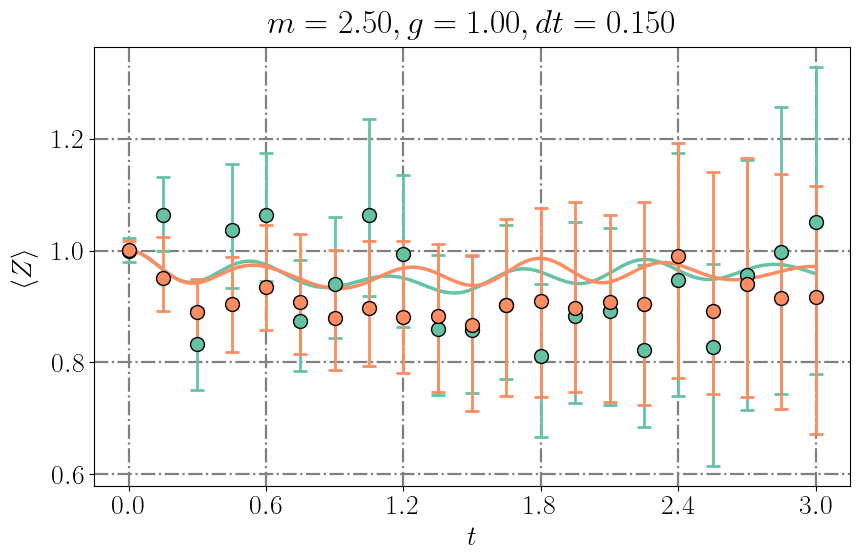

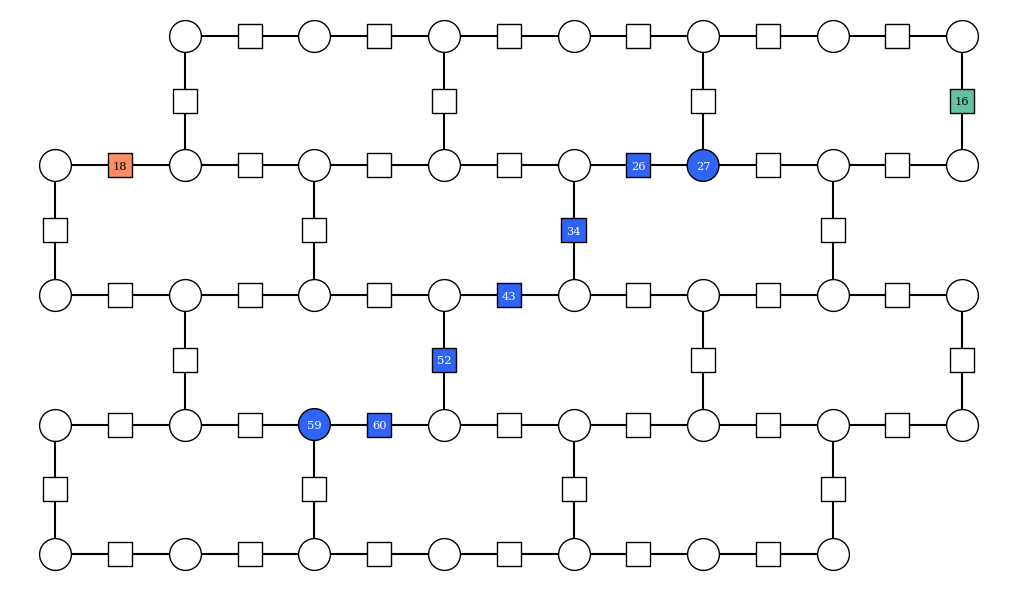

In [27]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [16, 18]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

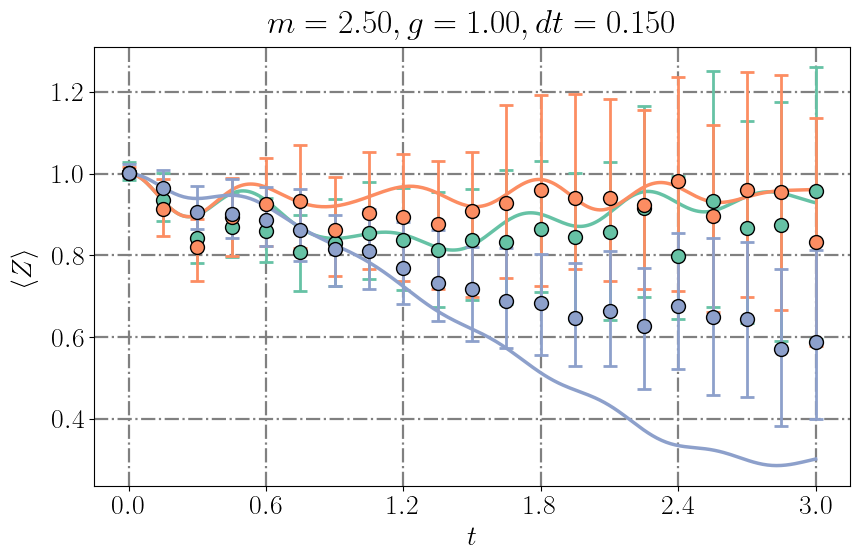

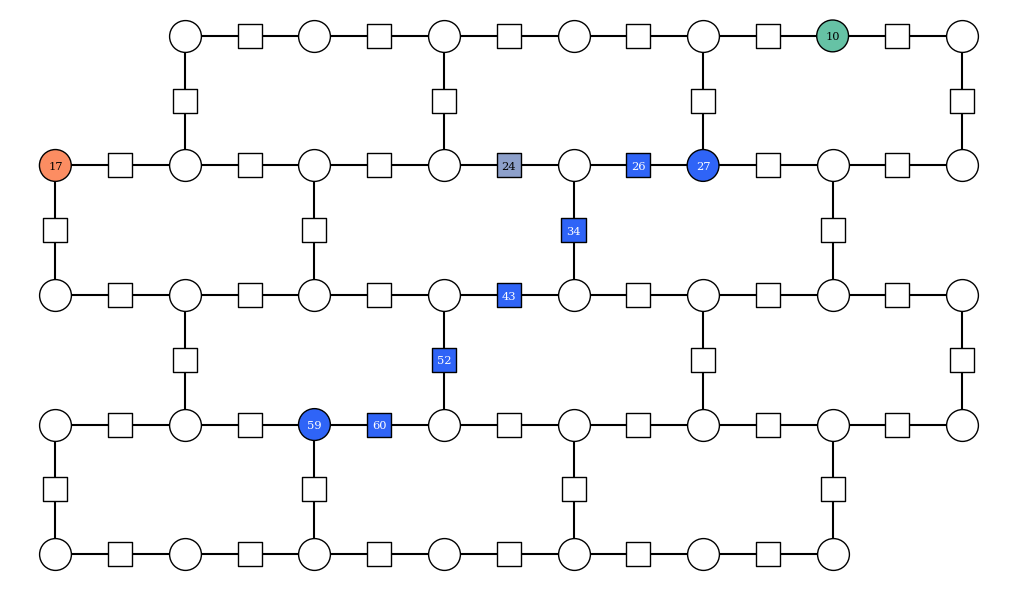

In [28]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [10, 17, 24]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

## 3x4

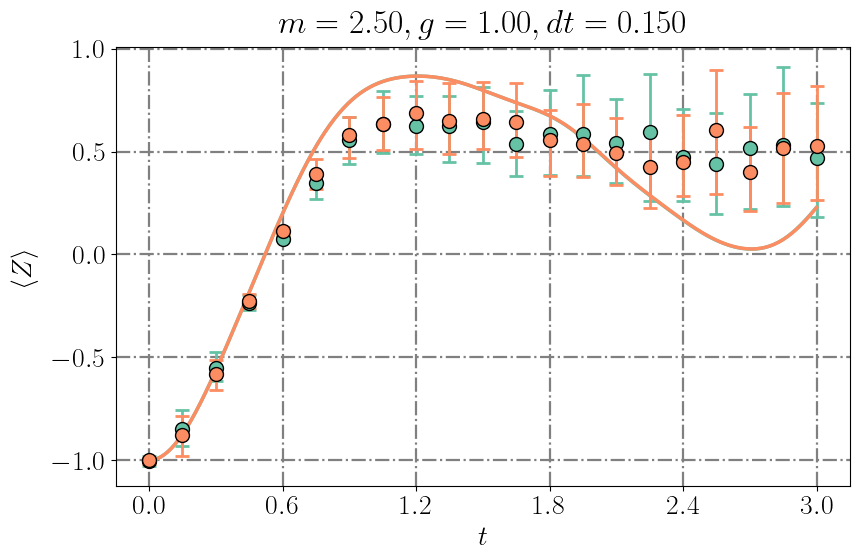

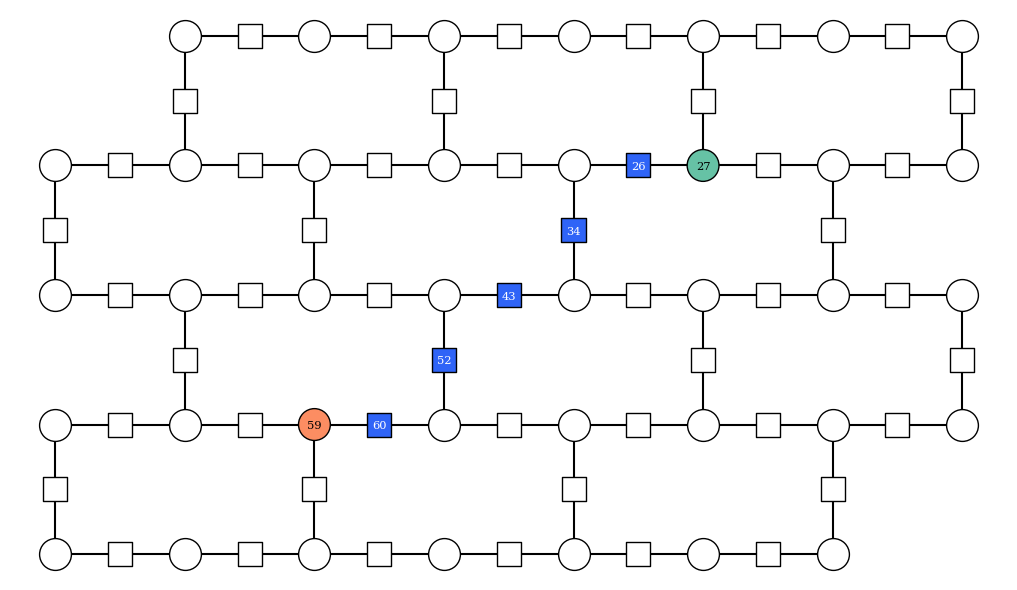

In [39]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [27, 59]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

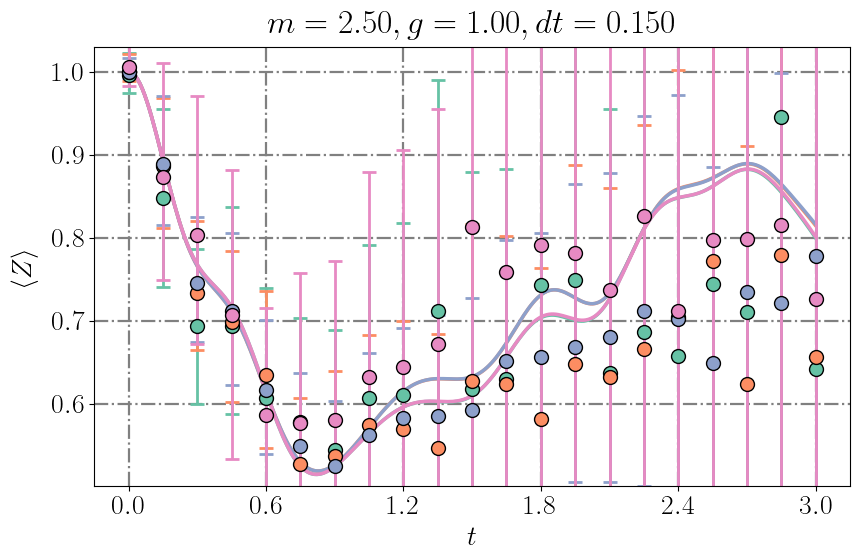

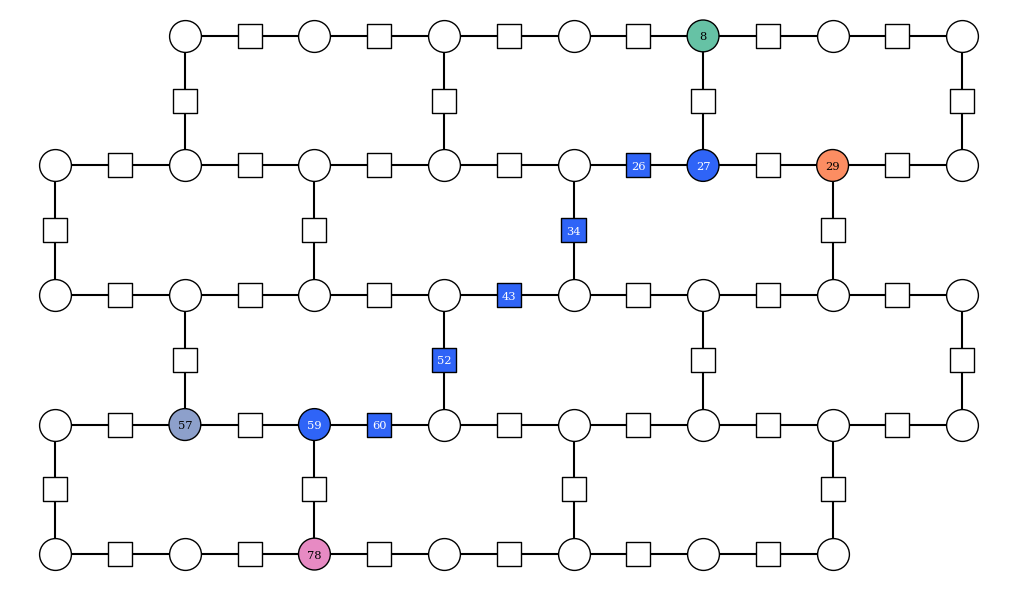

In [40]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [8, 29, 57, 78]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

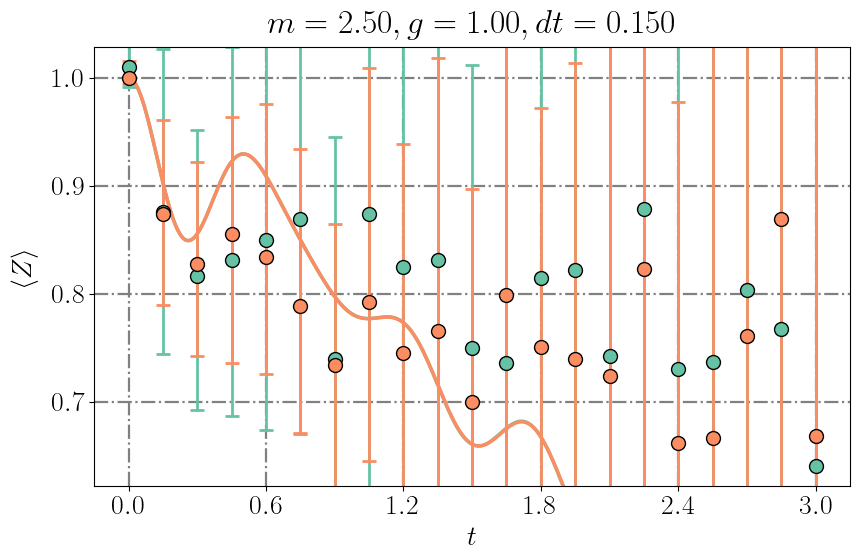

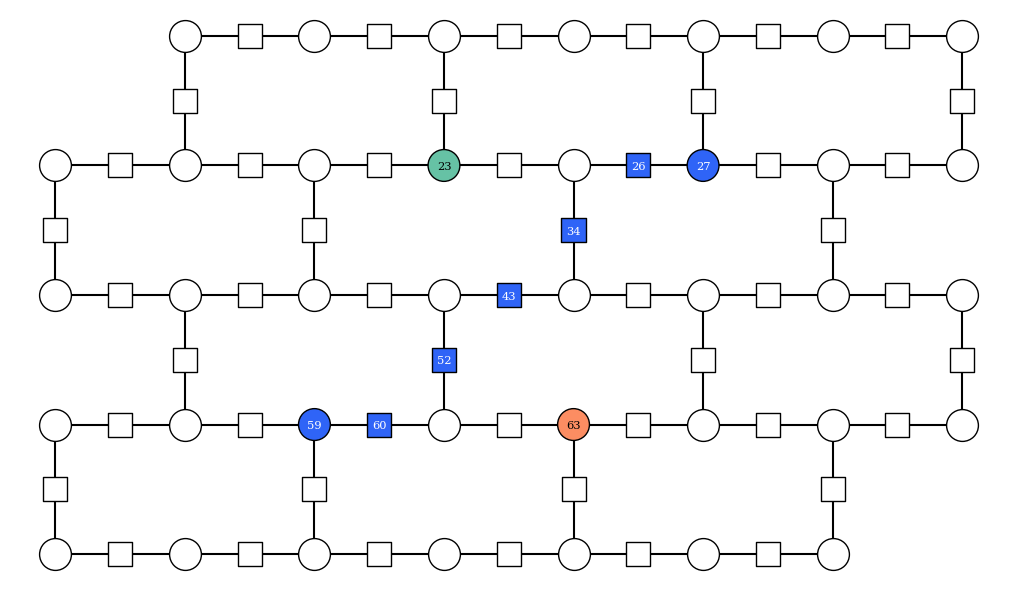

In [41]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [23, 63]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

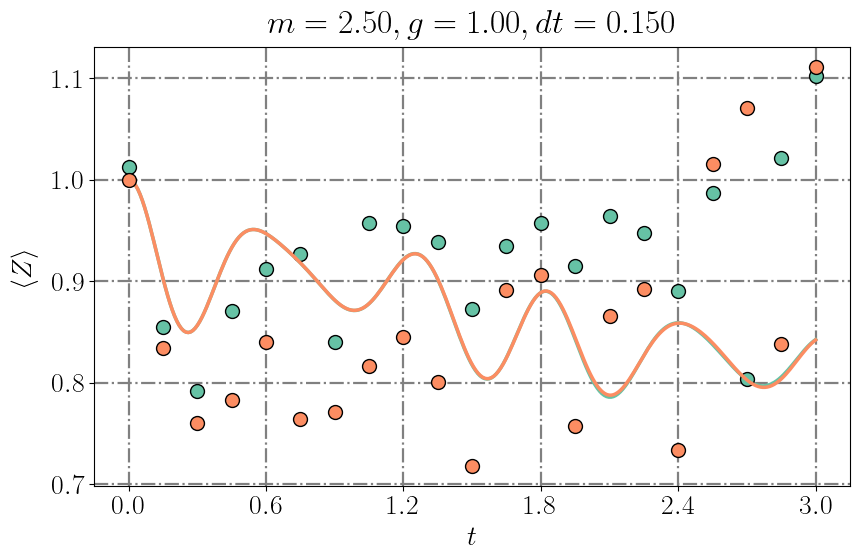

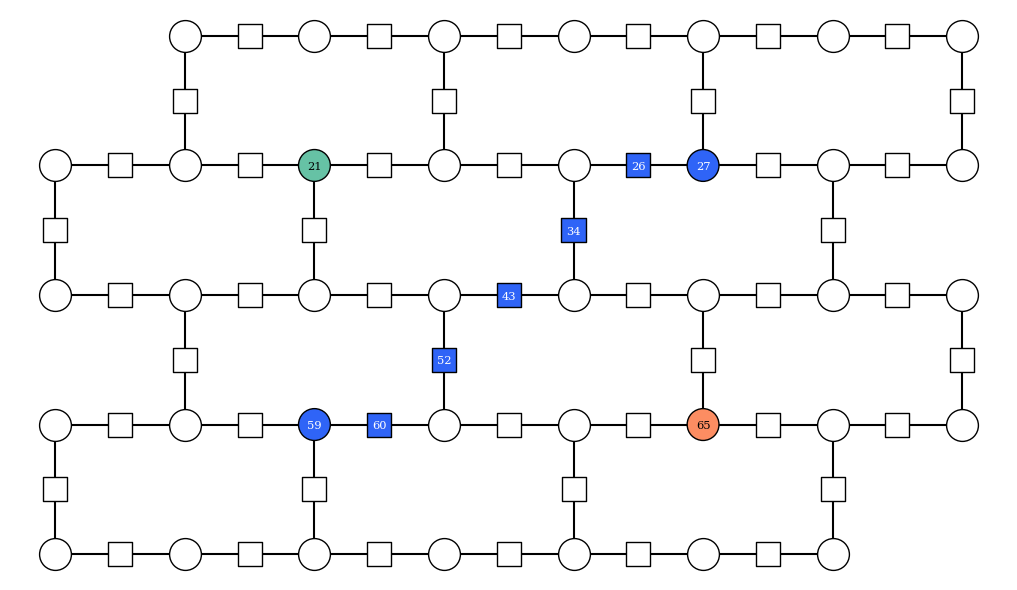

In [42]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [21, 65]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = None #hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

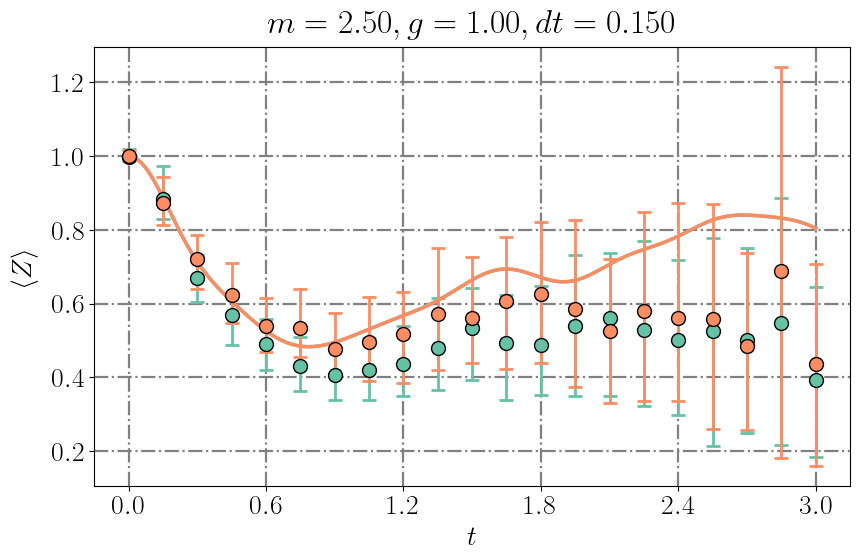

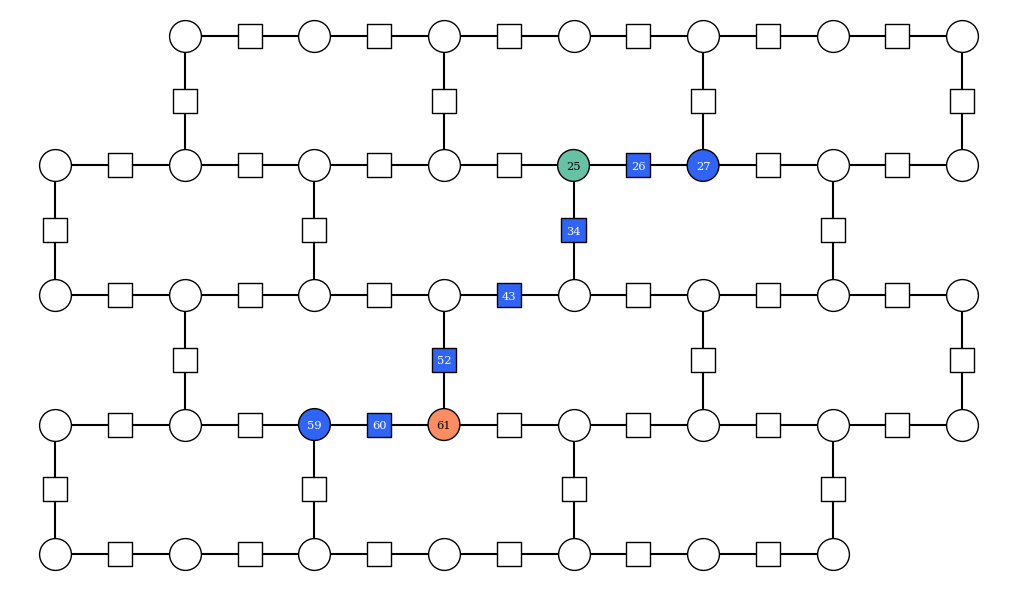

In [43]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [25, 61]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

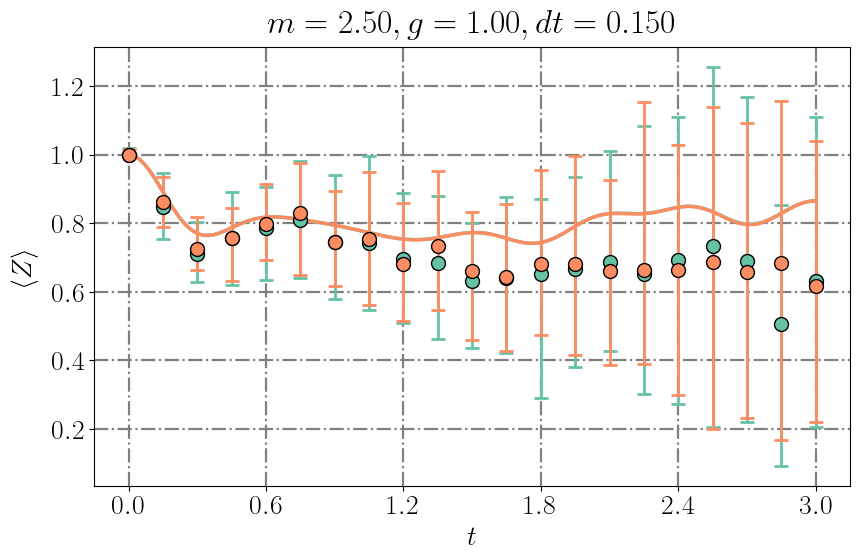

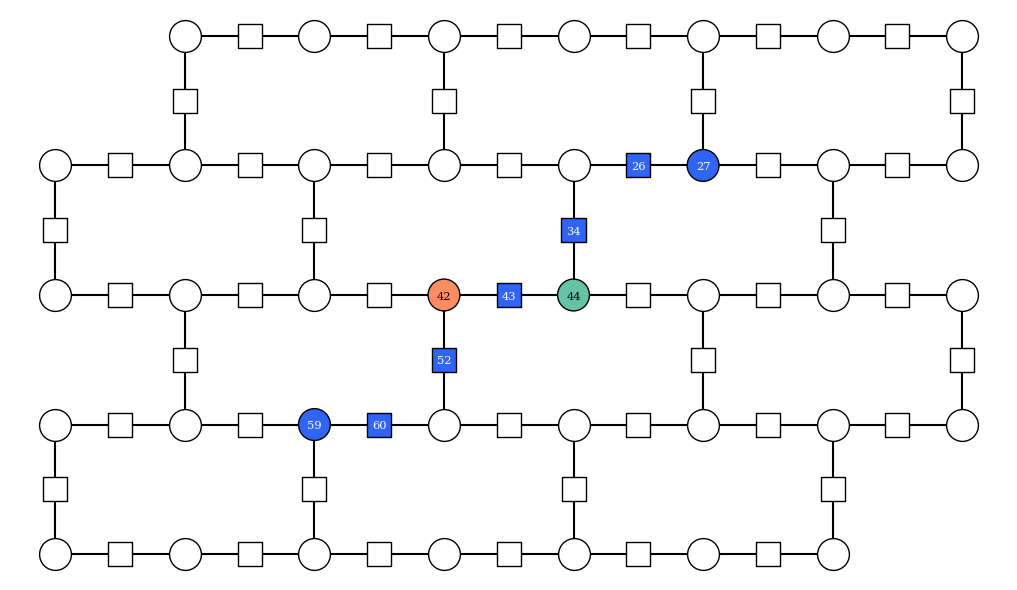

In [44]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [44, 42]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

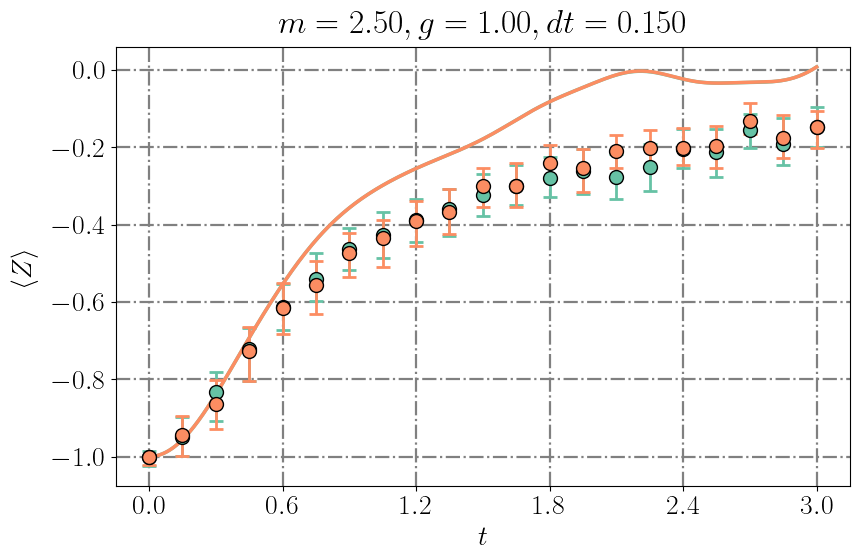

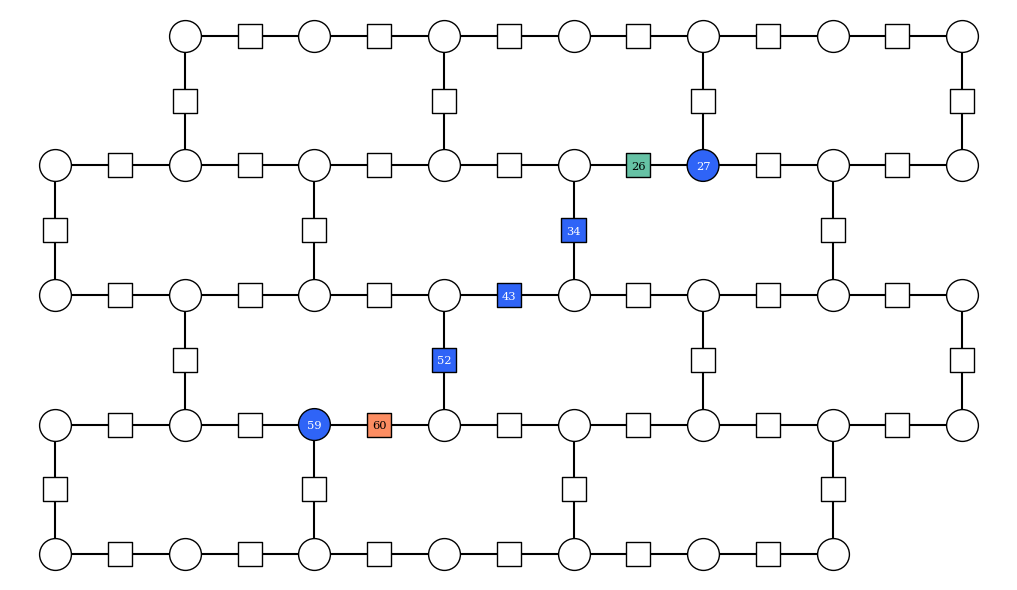

In [45]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [26, 60]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

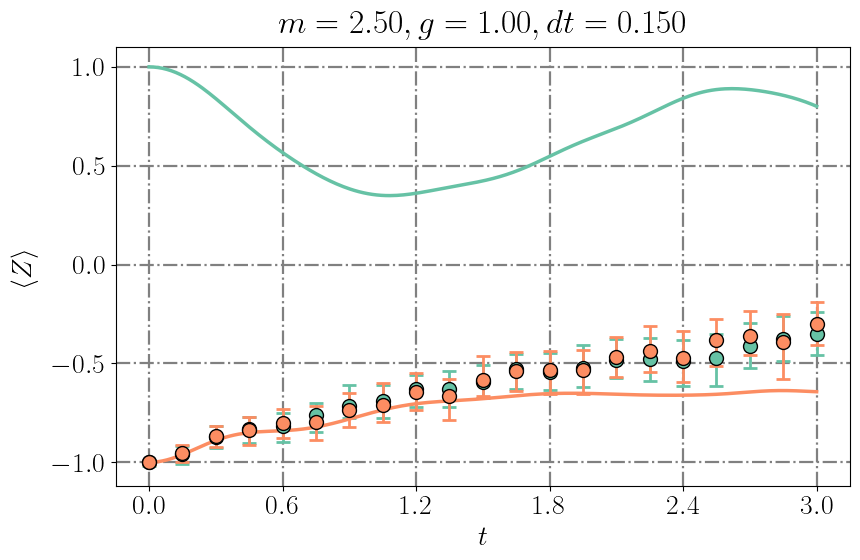

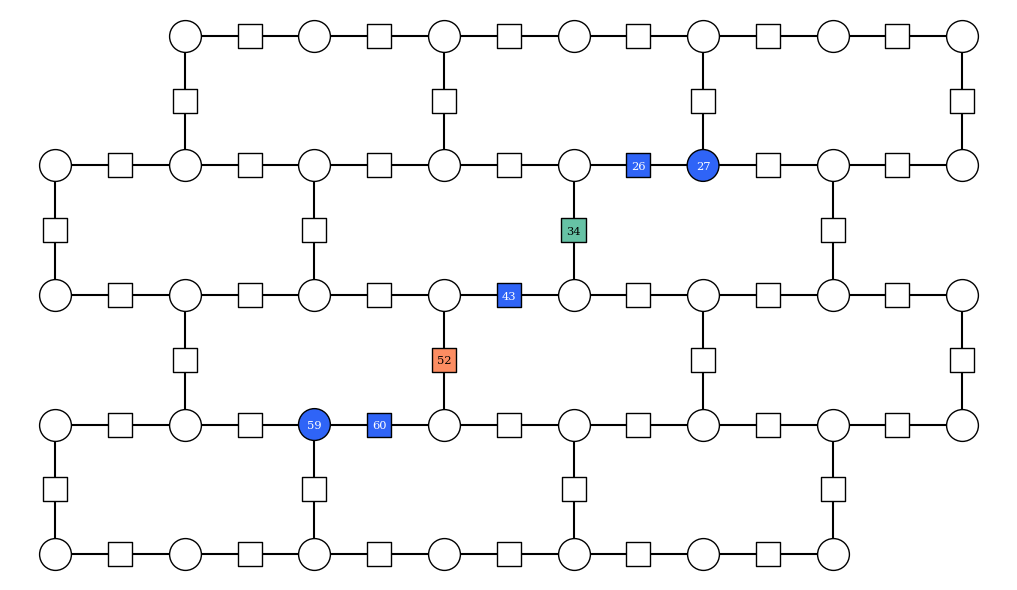

In [46]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [34, 52]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

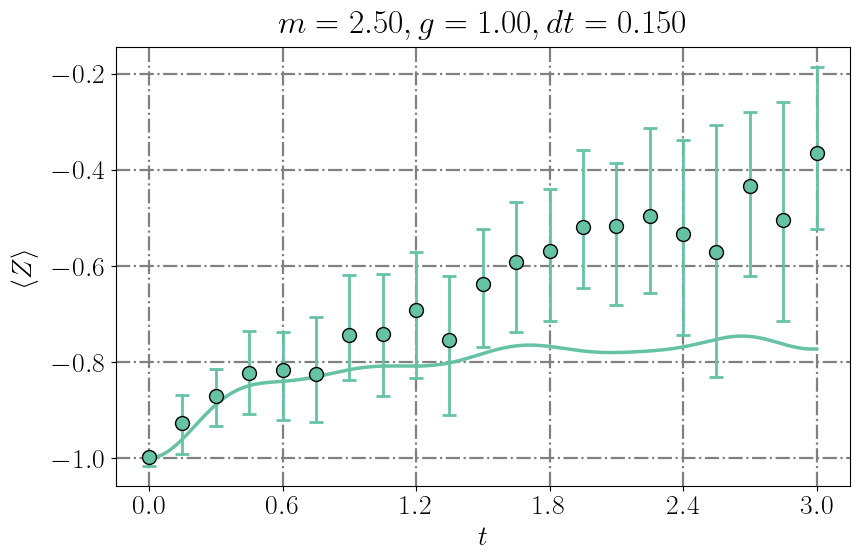

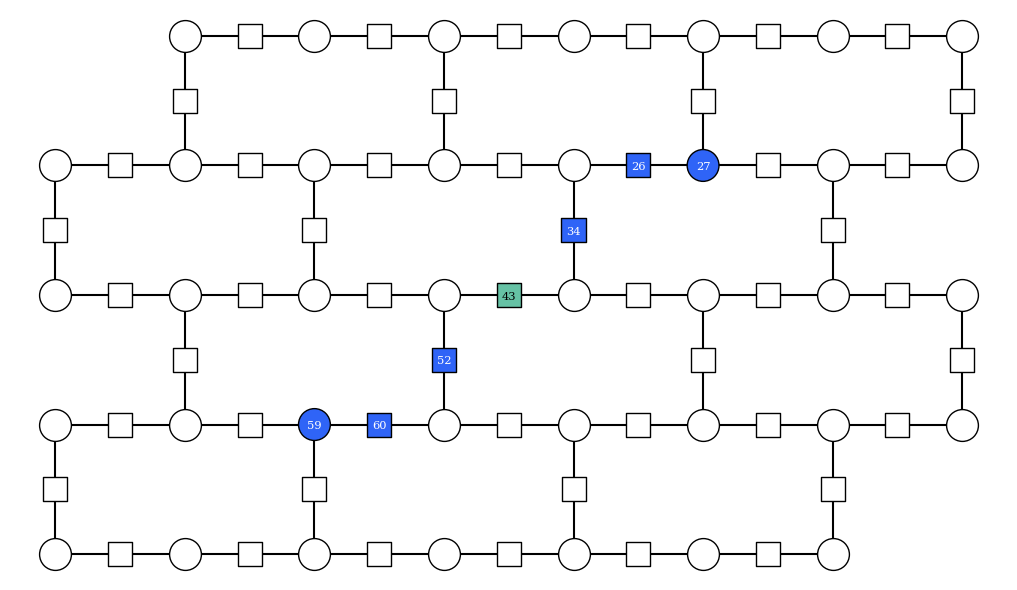

In [47]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [43]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

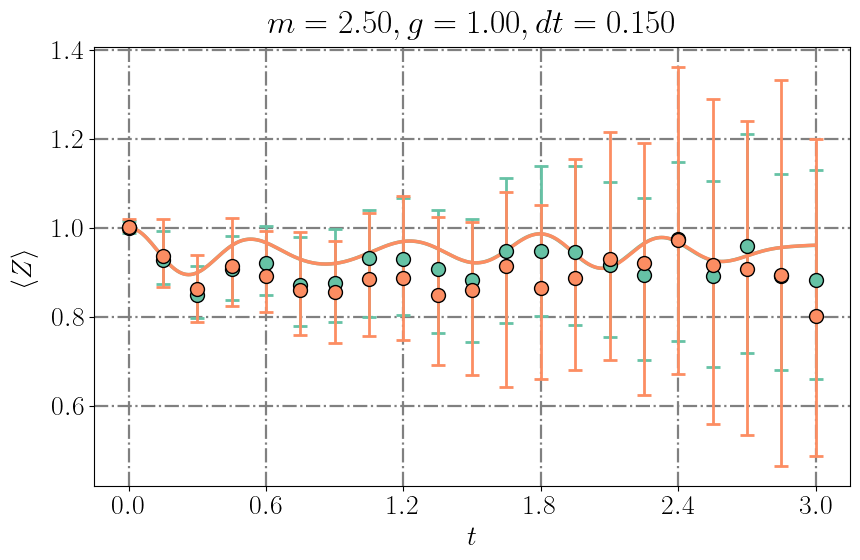

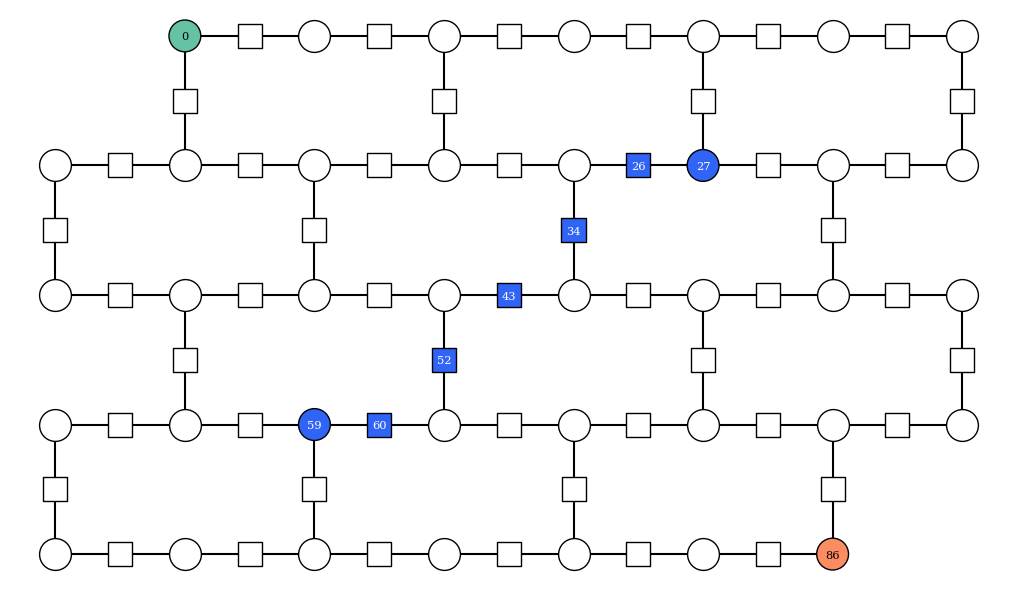

In [48]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [0, 86]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)